# Myocardial infarction: centering and intercept extension

**Targets:** $P(K=1)>1/2$ and most conditional change-location mass above age 55;
among those settings, a curve closer to the archived curve is preferable. This is exploratory
selection on the same data, not confirmatory evidence or proof of posterior calibration.

Centering the feature columns does not replace a logistic intercept: without an intercept,
the fitted probability at the mean feature vector is 1/2. The response rate is about 0.232.
With an unpenalized intercept and a fixed whitening/scaling transformation, centering is an exact
affine reparameterization; the notebook verifies this identity on the actual fitted predictions.
All data processing, prior count odds, age grid, and 110-feature design otherwise match the
preceding heuristic exploration. Here $\Delta=1$ throughout.

## Model-aware intercept branch

Fit unpenalized intercepts with weighted LS, or logistic L2 ($10^{-6}$) / L1 ($10^{-4}$)
for auxiliary signal-strength estimation. Keep logistic L2 ($10^{-8},10^{-6}$) and L1
($10^{-6},10^{-4}$) fits for posterior evaluation. Center adjusted scores by their fitted
total offsets. In the auxiliary squared-loss state equations, the fitted offset is the response
rate $r$, and the noise second-moment term becomes $r(1-r)$, not $1/2$.

Use the extended observation model $Y\mid Z_s\sim\mathrm{Bernoulli}(\sigma(\mu_s+Z_s))$.
At each proposed covariance, calibrate each $\mu_s$ to the **same global observed rate**
$E\sigma(\mu_s+N(0,\rho_{ss}))=r$. No pilot split or target change age is used to set that rate.
This is an explicit empirical-Bayes model extension; it is not silently passed off as the
original centered, zero-intercept observation model. The logistic state solve includes two
additional unknown fitted intercepts and their two mean-score equations. Evaluate the
correct joint density of the centered adjusted scores and the logistic observations, with
the response offsets included in the conditional observation probabilities.

Initialize $\rho=I_2$, retain 1/3/10/30 damped updates (weight 0.25), with covariance eigenvalues
clipped to $[10^{-4},100]$. Add a directly optimized LS moment fit, with log standard deviations
in $[-8,\log 10]$ and correlation in $[-0.9999,0.9999]$. Return nonzero residuals rather than
rejecting estimates. Posterior states use 512 common scrambled Sobol draws, at most 100 nonlinear
solver evaluations, and 160-node likelihood quadrature. There are 52 comparisons in this branch.
Small fitting penalties still use approximately unpenalized state equations; no exact penalized
asymptotic theorem is claimed.

## Fit-only uncentered diagnostic

As a separate diagnostic, do not subtract feature means before applying the **same** whitening
transform, omit the intercept, recompute LS auxiliary estimates and all four logistic posterior
fits, and retain the original zero-mean equations. This deliberately tests the requested fitting
knob but violates that model's centered-design assumption. These 20 comparisons are explicitly
labeled and are not interchangeable with the model-aware intercept branch.

The preceding notebook retains the complete centered/no-intercept grid, numerical refinements,
and denser penalty sweep. Original reference files are not changed. All experiment code is visible below.


In [1]:
"""Reproducible exploratory grid, also embedded verbatim in its notebook."""
import os
for key in ('OPENBLAS_NUM_THREADS','OMP_NUM_THREADS','MKL_NUM_THREADS'):
    os.environ[key]='1'
from pathlib import Path
import pickle, hashlib, json, time, traceback
import numpy as np
import pandas as pd
from scipy.special import expit, logsumexp
from scipy.optimize import minimize
from joblib import Parallel, delayed, parallel_config
from WERM.signal_strength import (configuration_prior, empirical_adjustment,
    squared_logistic_state, gaussian_logistic_loglikelihood)
from WERM.myocardial_approximate import approximate_rho, logistic_state
from WERM.proximal import fit_weighted

DELTAS=(1,85,169)
FIT_SETTINGS=(('l2',1e-8),('l2',1e-6),('l1',1e-6),('l1',1e-4))
ITERATIONS=(1,3,10,30)
N_JOBS=36


def load_data():
    from scipy.linalg import eigh
    raw=pd.read_csv('results/myocardial_raw_uci579.csv')
    data=raw.loc[raw.AGE.notna()].copy()
    data=data.iloc[np.argsort(data.AGE.to_numpy())]
    ages=data.AGE.to_numpy(float);y=(data.ZSN.to_numpy()>0).astype(int)
    X=data[list(raw.columns[2:112])].to_numpy(float)
    X=np.where(np.isnan(X),np.nanmean(X,axis=0),X);X-=X.mean(axis=0)
    n,p=X.shape
    values,vectors=eigh(X.T@X/n+1e-6*np.eye(p))
    X=X@((vectors/np.sqrt(values))@vectors.T)/np.sqrt(n)
    _,indices=np.unique(ages,return_index=True)
    return X,y,ages,indices[indices>0]


def atomic_save(path,value):
    temp=path.with_suffix('.tmp')
    with temp.open('wb') as f:pickle.dump(value,f)
    temp.replace(path)


def fit_logistic(X,y,phi,penalty,strength):
    columns=[];checks=[]
    for w in phi:
        wn=w/w.sum()
        if penalty=='l2':
            def objective(beta):
                z=X@beta
                return float(wn@(np.logaddexp(0,z)-y*z)+strength*(beta@beta)), X.T@(wn*(expit(z)-y))+2*strength*beta
            fit=minimize(objective,np.zeros(X.shape[1]),jac=True,method='L-BFGS-B',
                         options=dict(maxiter=5000,ftol=1e-14,gtol=1e-10,maxcor=30))
            beta=fit.x;err=np.max(abs(objective(beta)[1]))
            checks.append(dict(kkt=float(err),iterations=fit.nit,success=bool(fit.success)))
        else:
            fit=fit_weighted(X,y,loss='logistic',sample_weight=w,penalty='l1',
                             penalty_strength=strength,max_iter=20000,tol=1e-8)
            beta=fit.coef
            checks.append(dict(kkt=fit.kkt_violation,iterations=fit.n_iter,success=fit.converged))
        columns.append(beta)
    theta=X@np.column_stack(columns)
    V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='logistic')
    return dict(theta=theta,V=V,b=b,checks=checks,penalty=penalty,strength=strength)


def pilot(theta,y,eta,loss):
    errors=(theta-y[:,None])**2 if loss=='squared' else np.logaddexp(0,theta)-y[:,None]*theta
    scores=[errors[:,0].sum() if e<0 else errors[:e,0].sum()+errors[e:,1].sum() for e in eta]
    e=int(eta[np.argmin(scores)])
    # Signal strength with two latent signals is not identified at a null pilot.
    return e, np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)


def project_covariance(matrix):
    values,vectors=np.linalg.eigh((matrix+matrix.T)/2)
    return (vectors*np.clip(values,1e-4,100.))@vectors.T


def rho_path(S,phi,psi,delta,loss):
    rho=np.eye(2);records=[]
    for iteration in range(1,max(ITERATIONS)+1):
        if loss=='squared':state=squared_logistic_state(rho,phi,psi,delta)
        else:state=logistic_state(rho,phi,psi,delta,sample_power=7,max_nfev=30)
        lam=state['lambda'];K=state['kappa'];inverse=np.linalg.pinv(lam,rcond=1e-6)
        target=project_covariance(inverse.T@(S-K)@inverse)
        rho=project_covariance(.75*rho+.25*target)
        if iteration in ITERATIONS:
            check=squared_logistic_state(rho,phi,psi,delta) if loss=='squared' else logistic_state(rho,phi,psi,delta,sample_power=8,max_nfev=60)
            records.append(dict(rho=rho.copy(),iteration=iteration,
                moment_residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S)),
                state_residual=check.get('training_residual',0.)))
    return records


def prepare(delta_min,root,X,y,ages,locations):
    path=root/f'fits_delta{delta_min}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    eta,prior,phi=configuration_prior(len(y),locations[(locations>=delta_min)&(locations<=len(y)-delta_min)])
    fits={f'{kind}_{strength:g}':fit_logistic(X,y,phi,kind,strength) for kind,strength in FIT_SETTINGS}
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='squared')
    auxiliary={'least_squares':dict(theta=theta,V=V,b=b),**fits}
    scenarios=[]
    for name,fit in auxiliary.items():
        loss='squared' if name=='least_squares' else 'logistic'
        e,psi=pilot(fit['theta'],y,eta,loss);S=fit['V'].T@fit['V']/len(y)
        for record in rho_path(S,phi,psi,len(y)/X.shape[1],loss):
            scenarios.append(dict(record,auxiliary=name,pilot=e,loss=loss))
        if loss=='squared':
            record=approximate_rho(S,phi,psi,len(y)/X.shape[1])
            scenarios.append(dict(rho=record['rho'],iteration=-1,moment_residual=record['residual_norm'],
                                  state_residual=0.,auxiliary=name,pilot=e,loss=loss))
    result=dict(eta=eta,prior=prior,phi=phi,fits=fits,scenarios=scenarios,delta_min=delta_min)
    atomic_save(path,result);return result


def evaluate_scenario(setting,scenario,X,y,ages,root,power=7,budget=40):
    label=f"d{setting['delta_min']}_{scenario['auxiliary']}_it{scenario['iteration']}_q{power}_b{budget}"
    path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    begin=time.monotonic();rho=scenario['rho'];eta=setting['eta'];phi=setting['phi']
    logweights={name:[] for name in setting['fits']};residuals=[];states=[]
    for e in eta:
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        state=logistic_state(rho,phi,psi,len(y)/X.shape[1],sample_power=power,max_nfev=budget)
        residuals.append(state['training_residual']);states.append(state)
        for name,fit in setting['fits'].items():
            logweights[name].append(gaussian_logistic_loglikelihood(fit['V'],y,rho,
                state['lambda'],state['kappa'],psi,quadrature_order=80))
    results={}
    for name,values in logweights.items():
        values=np.asarray(values);joint=values+np.log(setting['prior'])
        probs=np.exp(joint-logsumexp(joint));conditional=np.exp(values[1:]-logsumexp(values[1:]))
        results[name]=dict(log_likelihood=values,probabilities=probs,conditional=conditional,
                          presence=float(probs[1:].sum()),peak_age=float(ages[eta[1:][np.argmax(conditional)]]))
    result=dict(label=label,scenario=scenario,delta_min=setting['delta_min'],eta=eta,
                results=results,residuals=residuals,states=states,elapsed=time.monotonic()-begin)
    atomic_save(path,result);print('Completed',label,flush=True);return result


def run(smoke=False):
    X,y,ages,locations=load_data()
    specification=dict(deltas=DELTAS,fits=FIT_SETTINGS,iterations=ITERATIONS,
        damping=.25,eigenvalue_bounds=[1e-4,100],seed=42,primary_prior='half single null, half uniform admissible age grid',
        files={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
               ['tools/myocardial_exploration.py','WERM/myocardial_approximate.py','WERM/signal_strength.py','results/myocardial_raw_uci579.csv']})
    fingerprint=hashlib.sha256(json.dumps(specification,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_exploration_'+fingerprint);root.mkdir(exist_ok=True)
    (root/'specification.json').write_text(json.dumps(specification,indent=2))
    print('Checkpoint directory:',root,flush=True)
    if smoke:
        eta,prior,phi=configuration_prior(len(y),locations)
        fit=fit_logistic(X,y,phi,'l2',1e-6)
        state=logistic_state(np.eye(2),phi,(np.arange(len(y))>=locations[30]).astype(int),len(y)/X.shape[1],sample_power=7,max_nfev=40)
        print('Smoke:',fit['checks'],state['training_residual'],flush=True)
        return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        settings=Parallel(n_jobs=3)(delayed(prepare)(d,root,X,y,ages,locations) for d in DELTAS)
        print('All auxiliary trajectories computed.',flush=True)
        results=Parallel(n_jobs=N_JOBS)(delayed(evaluate_scenario)(s,r,X,y,ages,root) for s in settings for r in s['scenarios'])
    rows=[]
    for result in results:
        for fit,stats in result['results'].items():
            rows.append(dict(label=result['label'],delta_min=result['delta_min'],auxiliary=result['scenario']['auxiliary'],
                rho_iterations=result['scenario']['iteration'],posterior_fit=fit,presence=stats['presence'],peak_age=stats['peak_age'],
                moment_residual=result['scenario']['moment_residual'],fp_residual_max=max(result['residuals'])))
    pd.DataFrame(rows).to_csv(root/'summary.csv',index=False)
    print('Full coarse exploration complete:',len(rows),'comparisons.',flush=True)
    return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
"""Additional centering/intercept experiment with explicit model separation."""

from tools.myocardial_exploration_refinement import evaluate_refined
from WERM.myocardial_intercept import (fit_with_intercept,squared_intercept_state,
    logistic_intercept_state,intercept_loglikelihood)
from scipy.optimize import least_squares


def uncentered_design():
    from scipy.linalg import eigh
    raw=pd.read_csv('results/myocardial_raw_uci579.csv')
    data=raw.loc[raw.AGE.notna()].copy();data=data.iloc[np.argsort(data.AGE.to_numpy())]
    values=data[list(raw.columns[2:112])].to_numpy(float)
    values=np.where(np.isnan(values),np.nanmean(values,axis=0),values)
    mean=values.mean(axis=0);centered=values-mean
    eig,vec=eigh(centered.T@centered/len(values)+1e-6*np.eye(values.shape[1]))
    transform=((vec/np.sqrt(eig))@vec.T)/np.sqrt(len(values))
    return values@transform,mean@transform


def offset_rho_path(S,phi,psi,delta,rate,loss):
    def state_at(rho,power=7,budget=40):
        return squared_intercept_state(rho,phi,psi,delta,rate) if loss=='squared' else logistic_intercept_state(
            rho,phi,psi,delta,rate,sample_power=power,max_nfev=budget)
    rho=np.eye(2);records=[]
    for iteration in range(1,31):
        state=state_at(rho);inv=np.linalg.pinv(state['lambda'],rcond=1e-6)
        target=project_covariance(inv.T@(S-state['kappa'])@inv)
        rho=project_covariance(.75*rho+.25*target)
        if iteration in ITERATIONS:
            check=state_at(rho,power=8,budget=60)
            records.append(dict(rho=rho.copy(),iteration=iteration,
                moment_residual=float(np.linalg.norm(check['lambda'].T@rho@check['lambda']+check['kappa']-S)),
                state_residual=check.get('training_residual',0.)))
    if loss=='squared':
        def decode(x):
            sd=np.exp(x[:2]);return np.array([[sd[0]**2,x[2]*sd.prod()],[x[2]*sd.prod(),sd[1]**2]])
        def residual(x):return (state_at(decode(x))['moment']-S).ravel()
        fits=[least_squares(residual,[v,v,0.],bounds=([-8,-8,-.9999],[np.log(10),np.log(10),.9999]),
                   max_nfev=500,ftol=1e-10,xtol=1e-10,gtol=1e-10) for v in (-2.,-1.,0.)]
        best=min(fits,key=lambda f:np.linalg.norm(f.fun))
        records.append(dict(rho=decode(best.x),iteration=-1,moment_residual=float(np.linalg.norm(best.fun)),
                            state_residual=0.,optimizer_success=bool(best.success)))
    return records


def offset_prepare(root,X,y,ages,locations):
    path=root/'offset_fits.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    eta,prior,phi=configuration_prior(len(y),locations)
    fits={f'{k}_{v:g}':fit_with_intercept(X,y,phi,k,v) for k,v in FIT_SETTINGS}
    auxiliary={'least_squares':fit_with_intercept(X,y,phi,'none',0.,loss='squared'),
               'l2_1e-06':fits['l2_1e-06'],'l1_0.0001':fits['l1_0.0001']}
    scenarios=[]
    for name,fit in auxiliary.items():
        loss='squared' if name=='least_squares' else 'logistic'
        e,psi=pilot(fit['theta'],y,eta,loss);S=fit['V'].T@fit['V']/len(y)
        for record in offset_rho_path(S,phi,psi,len(y)/X.shape[1],y.mean(),loss):
            scenarios.append(dict(record,auxiliary=name,pilot=e,loss=loss))
    Xraw,shift=uncentered_design();affine=[]
    np.testing.assert_allclose(Xraw-shift,X,atol=2e-12)
    for name,fit in fits.items():
        transformed_intercept=fit['intercepts']-shift@fit['coef']
        prediction=Xraw@fit['coef']+transformed_intercept
        affine.append(dict(fit=name,max_prediction_difference=float(np.max(abs(prediction-fit['theta'])))))
    result=dict(eta=eta,prior=prior,phi=phi,fits=fits,scenarios=scenarios,rate=y.mean(),affine=affine)
    atomic_save(path,result);return result


def offset_case(setting,scenario,X,y,ages,root,power=9,budget=100):
    label=f"offset_{scenario['auxiliary']}_it{scenario['iteration']}_q{power}_b{budget}"
    path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    values={name:[] for name in setting['fits']};states=[]
    for e in setting['eta']:
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        state=logistic_intercept_state(scenario['rho'],setting['phi'],psi,len(y)/X.shape[1],setting['rate'],
                                      sample_power=power,max_nfev=budget)
        states.append(state)
        for name,fit in setting['fits'].items():
            values[name].append(intercept_loglikelihood(fit['V'],y,scenario['rho'],state,psi))
    results={}
    for name,ll in values.items():
        ll=np.array(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint))
        curve=np.exp(ll[1:]-logsumexp(ll[1:]))
        results[name]=dict(P_1=probs[1:].sum(),conditional=curve,
            mass_above55=curve[ages[setting['eta'][1:]]>55].sum(),log_likelihood=ll,
            peak_age=ages[setting['eta'][1:][np.argmax(curve)]])
    result=dict(label=label,scenario=scenario,states=states,results=results,eta=setting['eta'])
    atomic_save(path,result);print('Completed',label,flush=True);return result


def uncentered_prepare(root,y,ages,locations):
    path=root/'uncentered_fits.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    X,shift=uncentered_design();eta,prior,phi=configuration_prior(len(y),locations)
    fits={f'{k}_{v:g}':fit_logistic(X,y,phi,k,v) for k,v in FIT_SETTINGS}
    B=np.column_stack([np.linalg.lstsq(X*np.sqrt(w[:,None]),y*np.sqrt(w),rcond=None)[0] for w in phi])
    theta=X@B;V,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss='squared')
    e,psi=pilot(theta,y,eta,'squared');S=V.T@V/len(y)
    scenarios=[dict(r,auxiliary='uncentered_least_squares',pilot=e,loss='squared') for r in rho_path(S,phi,psi,len(y)/X.shape[1],'squared')]
    direct=approximate_rho(S,phi,psi,len(y)/X.shape[1])
    scenarios.append(dict(rho=direct['rho'],iteration=-1,moment_residual=direct['residual_norm'],state_residual=0.,
                          auxiliary='uncentered_least_squares',pilot=e,loss='squared'))
    result=dict(eta=eta,prior=prior,phi=phi,fits=fits,scenarios=scenarios,delta_min=1)
    atomic_save(path,result);return result


def run_intercept_exploration():
    X,y,ages,locations=load_data()
    provenance={p:hashlib.sha256(Path(p).read_bytes()).hexdigest() for p in
        ['tools/myocardial_intercept_exploration.py','WERM/myocardial_intercept.py','WERM/myocardial_numerics.py']}
    fingerprint=hashlib.sha256(json.dumps(provenance,sort_keys=True).encode()).hexdigest()[:12]
    root=Path('results')/('myocardial_intercept_exploration_'+fingerprint);root.mkdir(exist_ok=True)
    (root/'provenance.json').write_text(json.dumps(provenance,indent=2))
    print('Intercept extension:',root,flush=True)
    offset=offset_prepare(root,X,y,ages,locations)
    uncentered=uncentered_prepare(root,y,ages,locations)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        results=Parallel(n_jobs=26)(delayed(offset_case)(offset,r,X,y,ages,root) for r in offset['scenarios'])
        diagnostics=Parallel(n_jobs=5)(delayed(evaluate_refined)(uncentered,r,X,y,ages,root,9,100) for r in uncentered['scenarios'])
    rows=[]
    for rec in results:
        for fit,stats in rec['results'].items():
            rows.append(dict(model='prevalence-calibrated intercept',setting=rec['label'],posterior_fit=fit,
                P_1=stats['P_1'],mass_above55=stats['mass_above55'],peak_age=stats['peak_age'],
                moment_residual=rec['scenario']['moment_residual'],FP_residual_max=max(s['training_residual'] for s in rec['states'])))
    for rec in diagnostics:
        for fit,stats in rec['results'].items():
            rows.append(dict(model='uncentered fit, old equations (diagnostic)',setting=rec['label'],posterior_fit=fit,
                P_1=stats['presence'],mass_above55=stats['conditional'][ages[rec['eta'][1:]]>55].sum(),peak_age=stats['peak_age'],
                moment_residual=rec['scenario']['moment_residual'],FP_residual_max=max(rec['residuals'])))
    pd.DataFrame(rows).to_csv(root/'summary.csv',index=False)
    print('Intercept/centering extension complete:',len(rows),'comparisons.',flush=True)
    return root




In [3]:
output=run_intercept_exploration()

Intercept extension: results/myocardial_intercept_exploration_f53f59063391


Intercept/centering extension complete: 72 comparisons.


In [4]:

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from IPython.display import display
import jax
jax.config.update('jax_enable_x64',True)
reference=pickle.load(open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl','rb'))
X,y,ages,locations=load_data()
ref_ages=np.asarray(reference['unique_ages']).ravel();ref_mass=np.asarray(reference['posterior']).ravel()
keep=np.isfinite(ref_ages)&np.isin(ref_ages,ages[locations]);ref_ages=ref_ages[keep];ref_mass=ref_mass[keep];ref_mass/=ref_mass.sum()
ref_map=dict(zip(ref_ages,ref_mass));reference_vector=np.array([ref_map[a] for a in ages[locations]])
records=[pickle.load(p.open('rb')) for p in sorted(output.glob('offset_*_q9_b100.pkl'))]
summary=pd.read_csv(output/'summary.csv')
summary['meets_targets']=(summary.P_1>.5)&(summary.mass_above55>.5)
summary['TV_to_reference']=np.nan
for rec in records:
    for name,result in rec['results'].items():
        index=(summary.setting==rec['label'])&(summary.posterior_fit==name)
        summary.loc[index,'TV_to_reference']=.5*np.abs(result['conditional']-reference_vector).sum()
summary.to_csv(output/'summary_with_reference.csv',index=False)
fits=pickle.load((output/'offset_fits.pkl').open('rb'))
print('Centering with an intercept: exact reparameterization check')
display(pd.DataFrame(fits['affine']))
print('All outcomes, including diagnostics that retain inappropriate old mean equations:')
with pd.option_context('display.max_rows',100,'display.max_columns',20):display(summary)
eligible=summary[(summary.model=='prevalence-calibrated intercept')&summary.meets_targets].sort_values('TV_to_reference')
print('Model-aware intercept settings meeting both targets, ranked by curve similarity (exploratory):')
display(eligible)
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':14,
                     'axes.labelsize':16,'xtick.labelsize':12,'ytick.labelsize':12,'figure.dpi':150})


Centering with an intercept: exact reparameterization check


,fit,max_prediction_difference
0,l2_1e-08,3.552714e-14
1,l2_1e-06,7.993606e-15
2,l1_1e-06,3.197442e-14
3,l1_0.0001,5.773160e-15


All outcomes, including diagnostics that retain inappropriate old mean equations:


,model,setting,posterior_fit,P_1,mass_above55,peak_age,moment_residual,FP_residual_max,meets_targets,TV_to_reference
0,prevalence-calibrated intercept,offset_least_squares_it1_q9_b100,l2_1e-08,1.000000e+00,3.157669e-35,54.0,0.003819,6.652717e-10,False,1.000000
1,prevalence-calibrated intercept,offset_least_squares_it1_q9_b100,l2_1e-06,1.000000e+00,1.000000e+00,76.0,0.003819,6.652717e-10,True,0.908002
2,prevalence-calibrated intercept,offset_least_squares_it1_q9_b100,l1_1e-06,1.000000e+00,1.000000e+00,57.0,0.003819,6.652717e-10,True,1.000000
3,prevalence-calibrated intercept,offset_least_squares_it1_q9_b100,l1_0.0001,1.000000e+00,1.000000e+00,70.0,0.003819,6.652717e-10,True,0.999999
4,prevalence-calibrated intercept,offset_least_squares_it3_q9_b100,l2_1e-08,1.000000e+00,3.549155e-11,54.0,0.001795,6.253034e-10,False,1.000000
5,prevalence-calibrated intercept,offset_least_squares_it3_q9_b100,l2_1e-06,1.000000e+00,1.000000e+00,75.0,0.001795,6.253034e-10,True,0.961253
6,prevalence-calibrated intercept,offset_least_squares_it3_q9_b100,l1_1e-06,1.000000e+00,1.000000e+00,58.0,0.001795,6.253034e-10,True,1.000000
7,prevalence-calibrated intercept,offset_least_squares_it3_q9_b100,l1_0.0001,1.000000e+00,2.490339e-17,27.0,0.001795,6.253034e-10,False,0.904500
8,prevalence-calibrated intercept,offset_least_squares_it10_q9_b100,l2_1e-08,4.343077e-07,1.000000e+00,92.0,0.000549,5.565635e-10,False,0.950206
9,prevalence-calibrated intercept,offset_least_squares_it10_q9_b100,l2_1e-06,1.000000e+00,1.000000e+00,67.0,0.000549,5.565635e-10,True,1.000000


Model-aware intercept settings meeting both targets, ranked by curve similarity (exploratory):


,model,setting,posterior_fit,P_1,mass_above55,peak_age,moment_residual,FP_residual_max,meets_targets,TV_to_reference
45,prevalence-calibrated intercept,offset_l1_0.0001_it10_q9_b100,l2_1e-06,0.850393,1.000000,81.0,0.157522,7.125939e-10,True,0.345024
49,prevalence-calibrated intercept,offset_l1_0.0001_it30_q9_b100,l2_1e-06,0.552526,1.000000,85.0,0.113503,8.263400e-10,True,0.349611
41,prevalence-calibrated intercept,offset_l1_0.0001_it3_q9_b100,l2_1e-06,1.000000,1.000000,78.0,0.455381,5.489481e-10,True,0.814030
37,prevalence-calibrated intercept,offset_l1_0.0001_it1_q9_b100,l2_1e-06,1.000000,1.000000,78.0,0.706958,6.785031e-10,True,0.876800
1,prevalence-calibrated intercept,offset_least_squares_it1_q9_b100,l2_1e-06,1.000000,1.000000,76.0,0.003819,6.652717e-10,True,0.908002
21,prevalence-calibrated intercept,offset_l2_1e-06_it1_q9_b100,l2_1e-06,1.000000,1.000000,76.0,0.385701,7.765685e-10,True,0.939924
5,prevalence-calibrated intercept,offset_least_squares_it3_q9_b100,l2_1e-06,1.000000,1.000000,75.0,0.001795,6.253034e-10,True,0.961253
25,prevalence-calibrated intercept,offset_l2_1e-06_it3_q9_b100,l2_1e-06,1.000000,1.000000,74.0,0.155715,5.829968e-11,True,0.983264
39,prevalence-calibrated intercept,offset_l1_0.0001_it1_q9_b100,l1_0.0001,1.000000,1.000000,70.0,0.706958,6.785031e-10,True,0.999213
43,prevalence-calibrated intercept,offset_l1_0.0001_it3_q9_b100,l1_0.0001,1.000000,0.999985,70.0,0.455381,5.489481e-10,True,0.999440


Logistic posterior fit: l2_1e-08


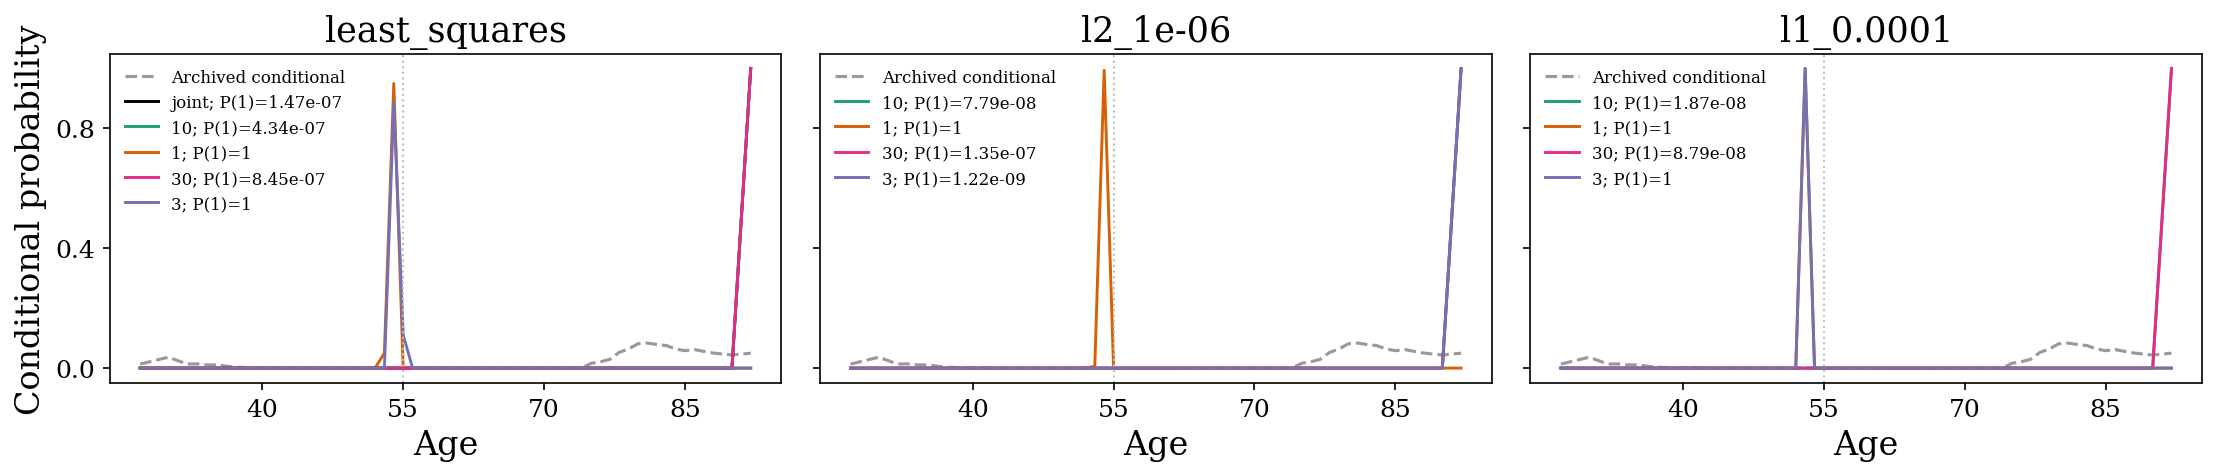

Logistic posterior fit: l2_1e-06


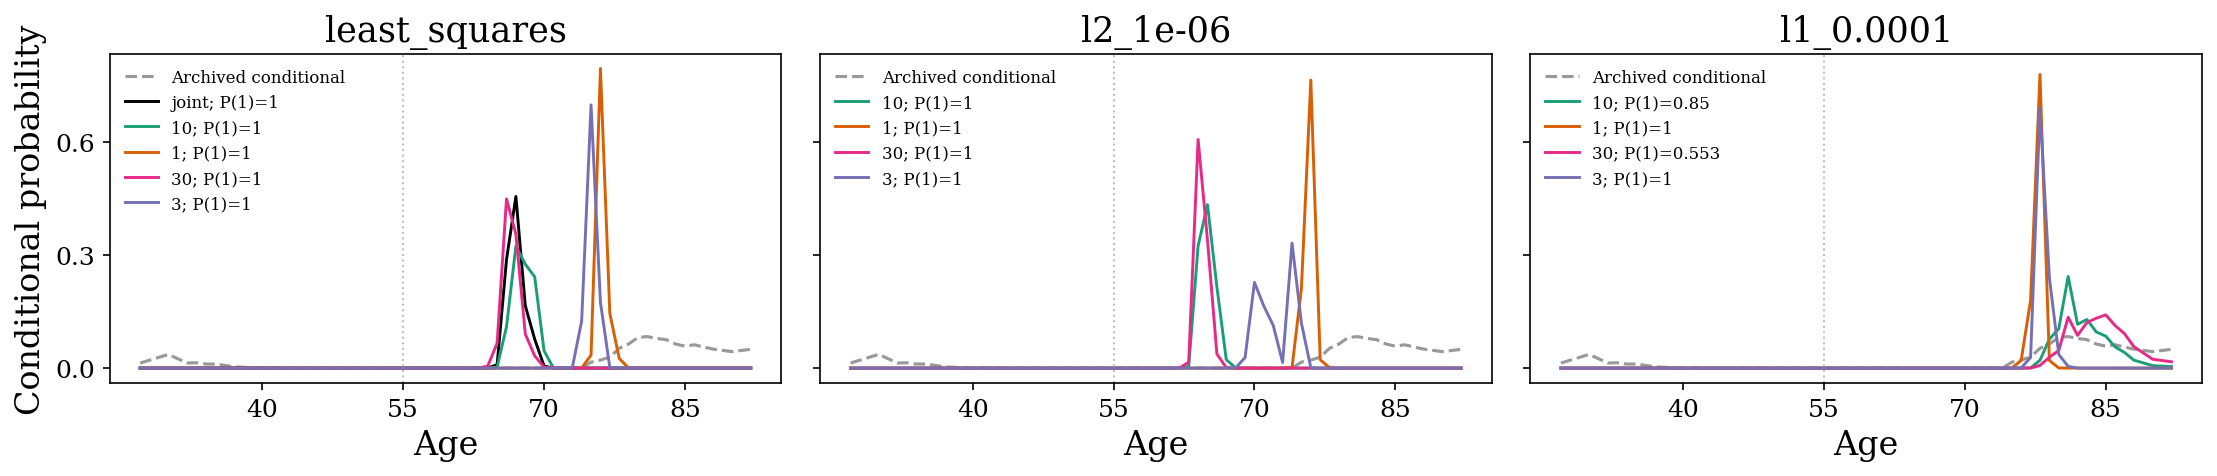

Logistic posterior fit: l1_1e-06


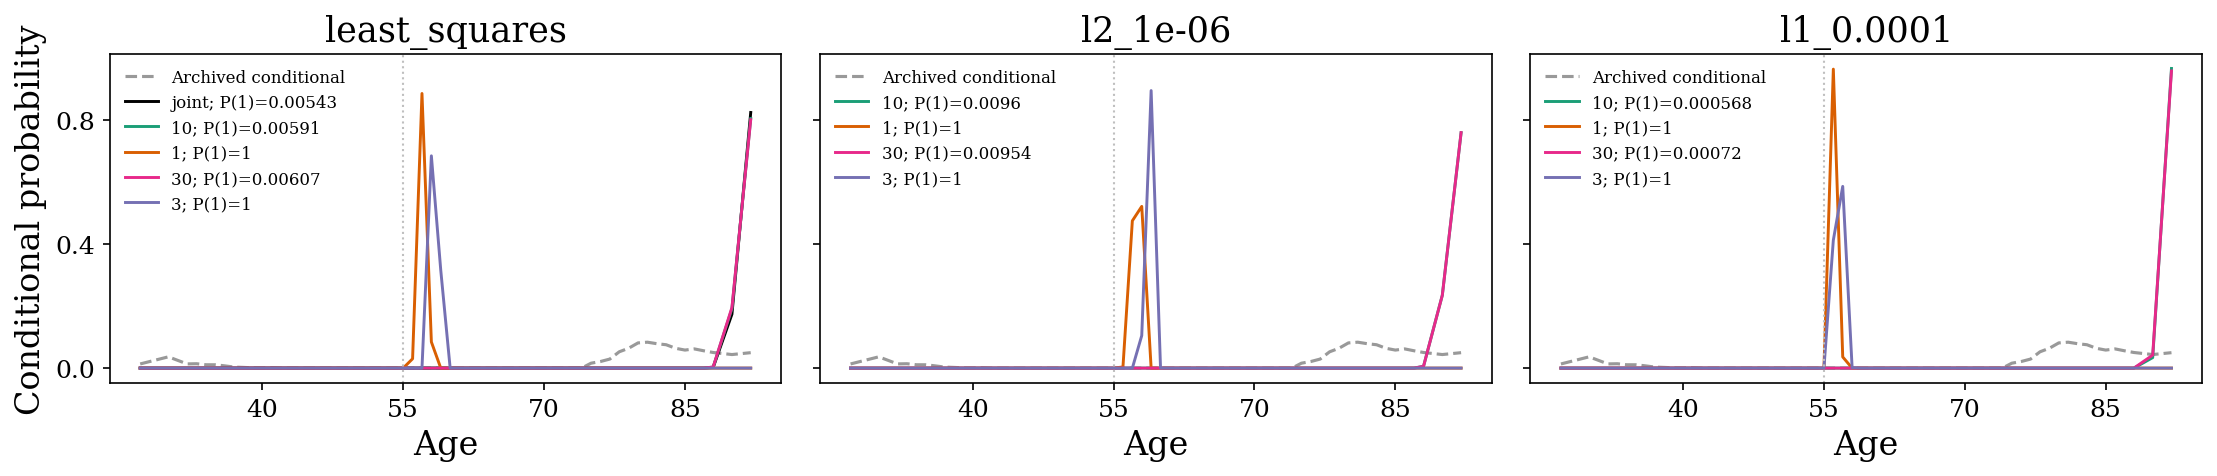

Logistic posterior fit: l1_0.0001


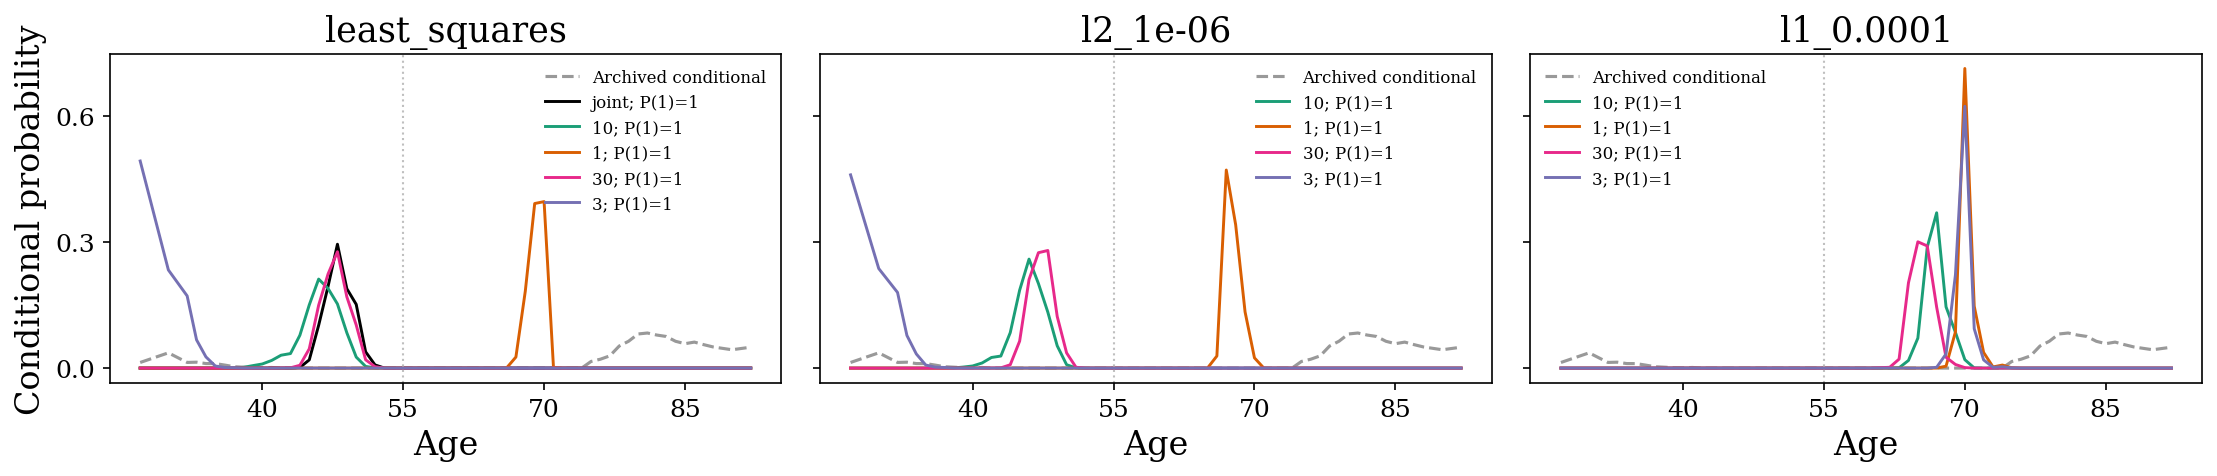

In [5]:

colors={1:'#d95f02',3:'#7570b3',10:'#1b9e77',30:'#e7298a',-1:'black'}
for fit in (f'{k}_{v:g}' for k,v in FIT_SETTINGS):
    print('Logistic posterior fit:',fit)
    fig,axes=plt.subplots(1,3,figsize=(15,3.4),sharex=True,sharey=True)
    for ax,aux in zip(axes,['least_squares','l2_1e-06','l1_0.0001']):
        ax.plot(ref_ages,ref_mass,color='.6',ls='--',label='Archived conditional')
        for rec in records:
            if rec['scenario']['auxiliary']!=aux:continue
            it=rec['scenario']['iteration'];result=rec['results'][fit]
            ax.plot(ages[locations],result['conditional'],color=colors[it],lw=1.4,
                label=('joint' if it==-1 else str(it))+f"; P(1)={result['P_1']:.3g}")
        ax.axvline(55,color='.75',ls=':',lw=1);ax.set_xlabel('Age');ax.set_title(aux)
        ax.set_xticks([40,55,70,85]);ax.yaxis.set_major_locator(ticker.MaxNLocator(3));ax.legend(fontsize=8,frameon=False)
    axes[0].set_ylabel('Conditional probability');fig.tight_layout();plt.show()


Closest eligible intercept curves; these are outcome-selected examples.
offset_l1_0.0001_it10_q9_b100 l2_1e-06 P(1)= 0.8503930557538452 P(age>55 | 1)= 0.9999999999999052 TV= 0.34502362004331155


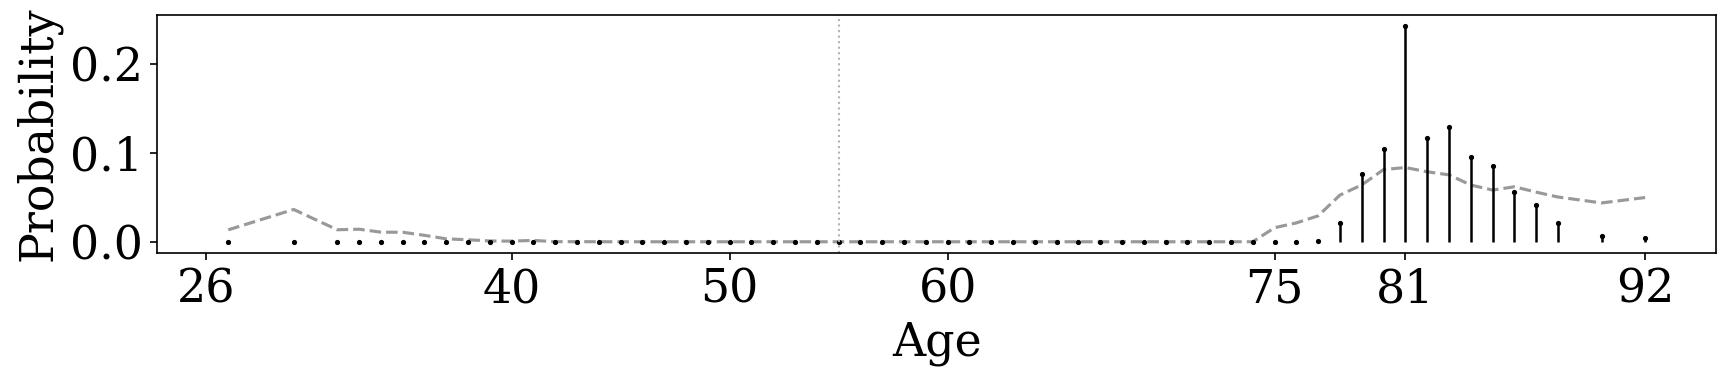

offset_l1_0.0001_it30_q9_b100 l2_1e-06 P(1)= 0.5525257318308022 P(age>55 | 1)= 0.999999999999845 TV= 0.34961149014748294


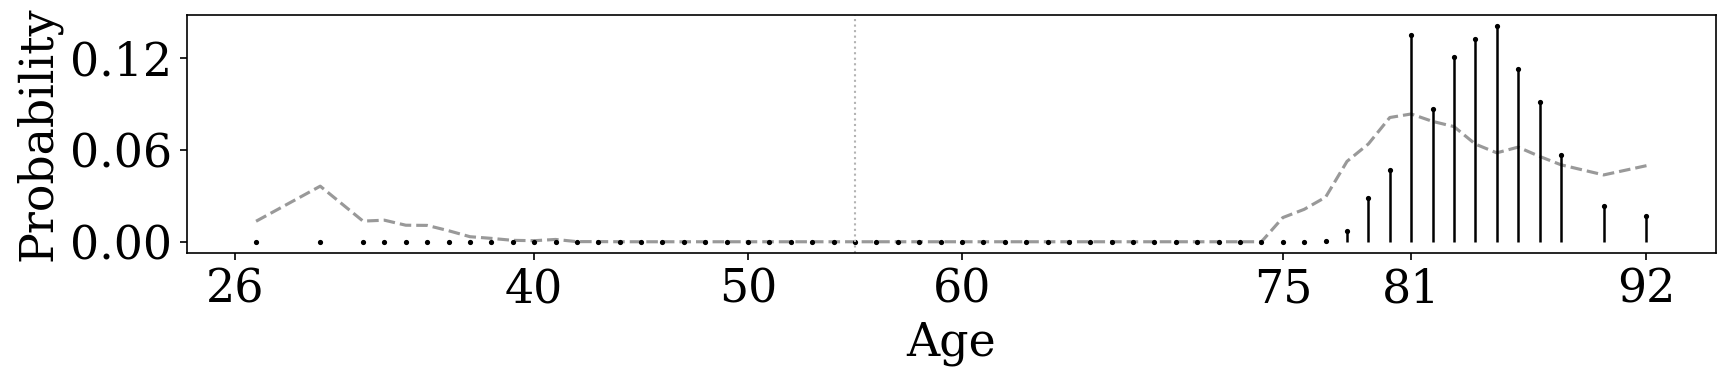

offset_l1_0.0001_it3_q9_b100 l2_1e-06 P(1)= 0.9999999998511196 P(age>55 | 1)= 0.999999999999822 TV= 0.8140296251623507


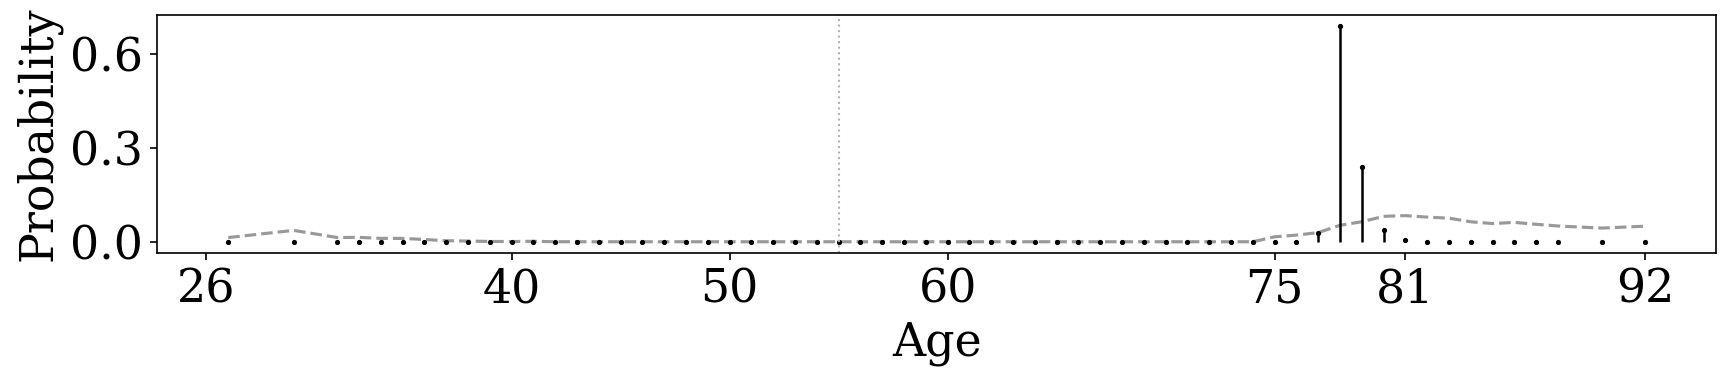

offset_l1_0.0001_it1_q9_b100 l2_1e-06 P(1)= 0.9999999999998304 P(age>55 | 1)= 0.9999999999998304 TV= 0.8767998453876701


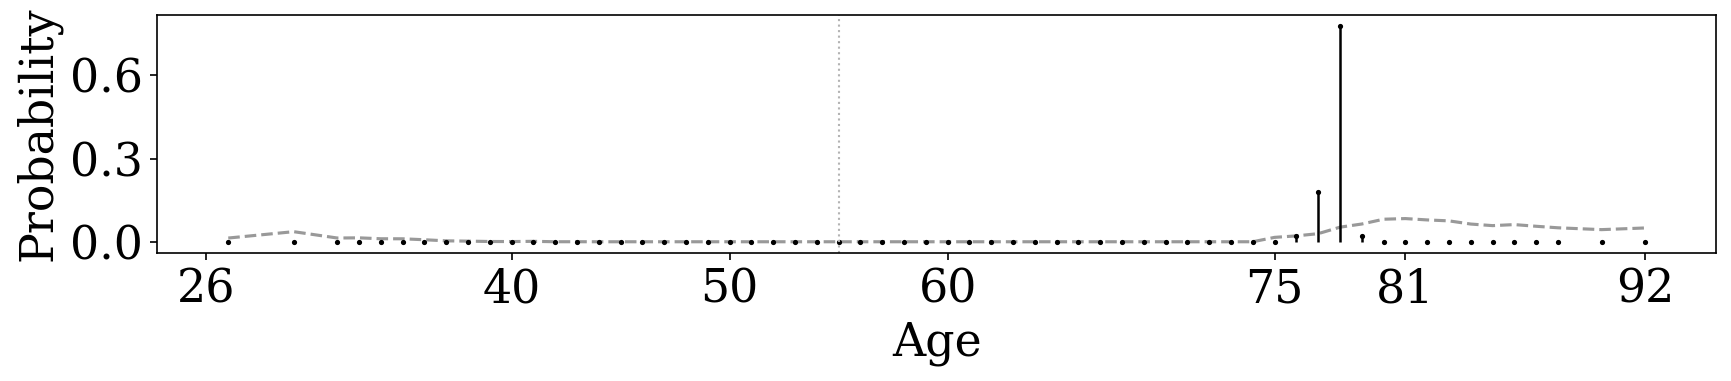

offset_least_squares_it1_q9_b100 l2_1e-06 P(1)= 0.9999999999999842 P(age>55 | 1)= 0.9999999999999842 TV= 0.9080018646179606


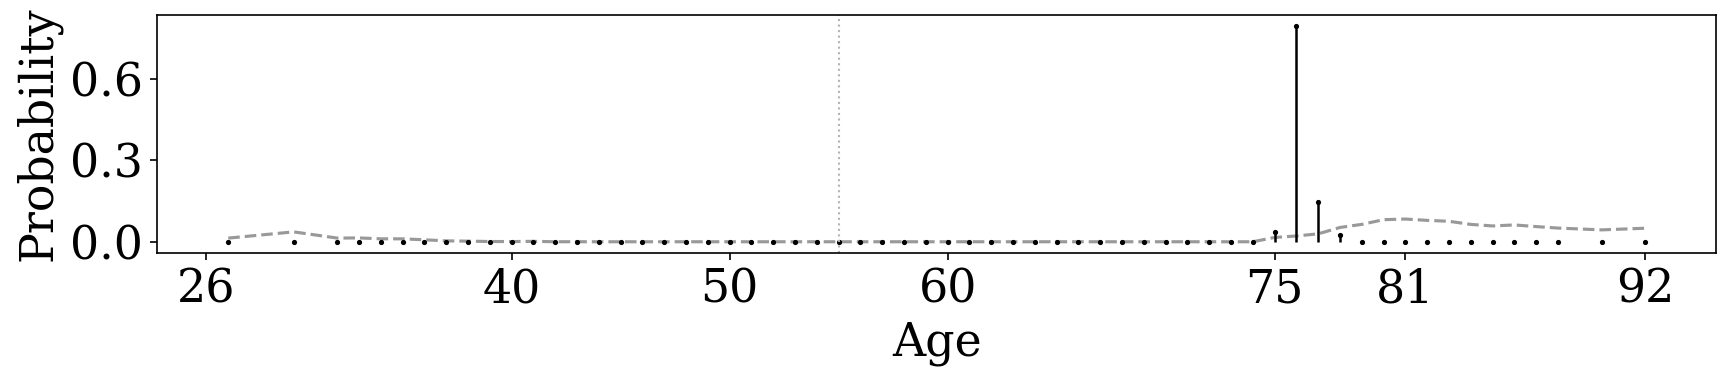

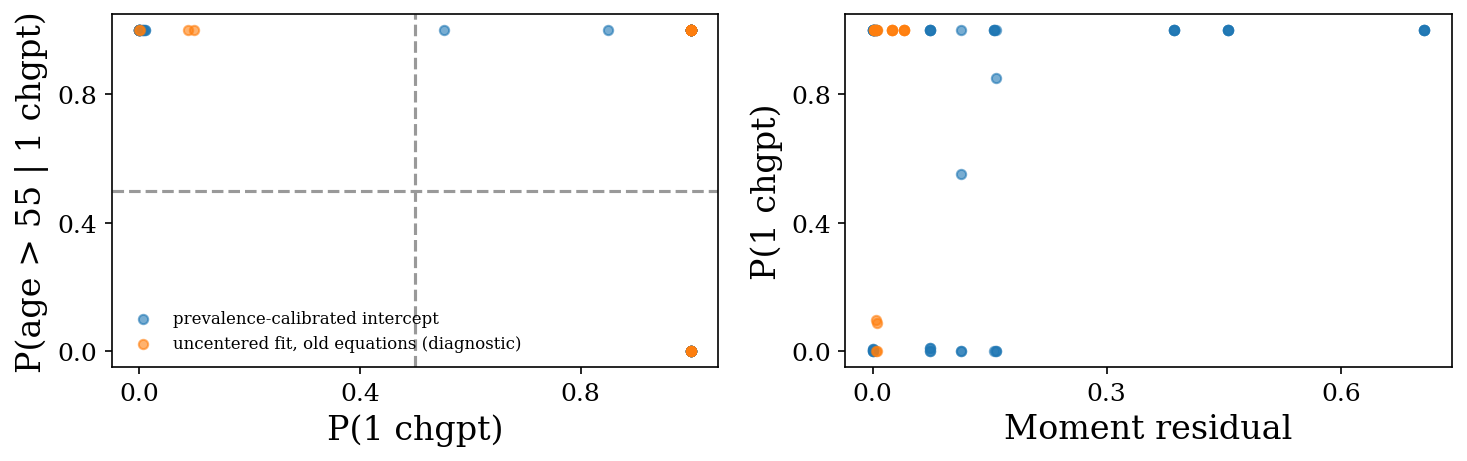

In [6]:

print('Closest eligible intercept curves; these are outcome-selected examples.')
for row in eligible.head(5).itertuples():
    rec=next(r for r in records if r['label']==row.setting);stats=rec['results'][row.posterior_fit]
    print(row.setting,row.posterior_fit,'P(1)=',row.P_1,'P(age>55 | 1)=',row.mass_above55,'TV=',row.TV_to_reference)
    with plt.rc_context({'font.size':22,'axes.labelsize':22,'xtick.labelsize':22,'ytick.labelsize':22}):
        fig,ax=plt.subplots(figsize=(12,3))
        ax.plot(ref_ages,ref_mass,color='.6',ls='--',lw=1.5)
        marker,stems,baseline=ax.stem(ages[locations],stats['conditional'],linefmt='k-',markerfmt='k.',basefmt=' ')
        plt.setp(stems,linewidth=1.2);plt.setp(marker,markersize=3)
        ax.axvline(55,color='.7',ls=':',lw=1);ax.set_xlabel('Age');ax.set_ylabel('Probability')
        ax.set_xticks([26,40,50,60,75,81,92]);ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
        fig.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,3.3))
for model,part in summary.groupby('model'):
    axes[0].scatter(part.P_1,part.mass_above55,s=20,alpha=.6,label=model)
    axes[1].scatter(part.moment_residual,part.P_1,s=20,alpha=.6,label=model)
axes[0].axvline(.5,color='.6',ls='--');axes[0].axhline(.5,color='.6',ls='--')
axes[0].set_xlabel('P(1 chgpt)');axes[0].set_ylabel('P(age > 55 | 1 chgpt)')
axes[1].set_xlabel('Moment residual');axes[1].set_ylabel('P(1 chgpt)')
axes[0].legend(fontsize=8,frameon=False)
for ax in axes:ax.xaxis.set_major_locator(ticker.MaxNLocator(3));ax.yaxis.set_major_locator(ticker.MaxNLocator(3))
fig.tight_layout();plt.show()


## Independent draws and final bounded penalty resolution

The two closest eligible initial settings used auxiliary logistic L1 strength $10^{-4}$ and
10/30 rho updates. Check independent seed 123 with 1,024 draws. Reuse both sets of states for
the same 22 logarithmic penalties as the main notebook, plus L2 strengths
$6\times10^{-7},8\times10^{-7},1.2\times10^{-6},1.5\times10^{-6},2\times10^{-6}$ around the
promising initial value. These are **outcome-informed exploratory refinements**, not independent
evidence for the selected setting. Keep all 54 settings and both numerical realizations.
Rank settings meeting both probability targets in both realizations by average TV to the archive.


In [7]:
"""Outcome-disclosed follow-up using independent QMC draws, not a new search."""



def independent_state(rho,phi,e,n,delta,offset_rate=None):
    psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
    if offset_rate is not None:
        from WERM.myocardial_intercept import logistic_intercept_state
        return logistic_intercept_state(rho,phi,psi,delta,offset_rate,sample_power=10,max_nfev=100,seed=123)
    import WERM.myocardial_approximate as m
    from WERM.myocardial_numerics import logistic_prox_fast
    original=m.logistic_prox;m.logistic_prox=logistic_prox_fast
    try:return m.logistic_state(rho,phi,psi,delta,sample_power=10,max_nfev=100,seed=123)
    finally:m.logistic_prox=original


def check_baseline(root):
    X,y,ages,locations=load_data();setting=pickle.load((root/'fits_delta1.pkl').open('rb'))
    eta=setting['eta'];phi=setting['phi'];rows=[]
    for iteration in (3,30):
        case=f'd1_least_squares_it{iteration}_q9_b100'
        old=pickle.load((root/(case+'.pkl')).open('rb'));rho=old['scenario']['rho']
        out=root/(case+'_independent_seed123_q10.pkl')
        if out.exists():states=pickle.load(out.open('rb'))
        else:
            with parallel_config(backend='loky',inner_max_num_threads=1):
                states=Parallel(n_jobs=18)(delayed(independent_state)(rho,phi,e,len(y),len(y)/X.shape[1]) for e in eta)
            atomic_save(out,states)
        for path in (root/'denser_penalty_grid').glob('fit_*.pkl'):
            name=path.stem[4:];fit=pickle.load(path.open('rb'))
            if 'error' in fit:continue
            ll=[]
            for e,state in zip(eta,states):
                psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
                ll.append(gaussian_logistic_loglikelihood(fit['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160))
            ll=np.asarray(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
            reference=pickle.load((root/'denser_penalty_grid'/(case+'_'+name+'.pkl')).open('rb'))
            rows.append(dict(case=case,posterior_fit=name,P_1=probs[1:].sum(),mass_above55=curve[ages[eta[1:]]>55].sum(),
                original_P_1=reference['P_1'],original_mass_above55=reference['mass_above55'],
                TV_from_original=.5*np.abs(curve-reference['conditional']).sum(),
                peak_age=ages[eta[1:][np.argmax(curve)]],FP_residual_max=max(s['training_residual'] for s in states)))
            atomic_save(root/'denser_penalty_grid'/(case+'_'+name+'_independent.pkl'),dict(conditional=curve,log_likelihood=ll,**rows[-1]))
    pd.DataFrame(rows).to_csv(root/'independent_draw_check.csv',index=False)
    print('Independent-draw follow-up complete.',flush=True)


def check_intercept(root):
    from WERM.myocardial_intercept import intercept_loglikelihood
    X,y,ages,locations=load_data();setting=pickle.load((root/'offset_fits.pkl').open('rb'))
    eta=setting['eta'];phi=setting['phi'];rows=[]
    for iteration in (10,30):
        case=f'offset_l1_0.0001_it{iteration}_q9_b100'
        old=pickle.load((root/(case+'.pkl')).open('rb'));rho=old['scenario']['rho']
        out=root/(case+'_independent_seed123_q10.pkl')
        if out.exists():states=pickle.load(out.open('rb'))
        else:
            with parallel_config(backend='loky',inner_max_num_threads=1):
                states=Parallel(n_jobs=18)(delayed(independent_state)(rho,phi,e,len(y),len(y)/X.shape[1],setting['rate']) for e in eta)
            atomic_save(out,states)
        for name,fit in setting['fits'].items():
            ll=[]
            for e,state in zip(eta,states):
                psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
                ll.append(intercept_loglikelihood(fit['V'],y,rho,state,psi))
            ll=np.asarray(ll);joint=ll+np.log(setting['prior']);probs=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
            reference=old['results'][name]
            rows.append(dict(case=case,posterior_fit=name,P_1=probs[1:].sum(),mass_above55=curve[ages[eta[1:]]>55].sum(),
                original_P_1=reference['P_1'],original_mass_above55=reference['mass_above55'],
                TV_from_original=.5*np.abs(curve-reference['conditional']).sum(),
                peak_age=ages[eta[1:][np.argmax(curve)]],FP_residual_max=max(s['training_residual'] for s in states)))
            atomic_save(root/(case+'_'+name+'_independent.pkl'),dict(conditional=curve,log_likelihood=ll,**rows[-1]))
    pd.DataFrame(rows).to_csv(root/'independent_draw_check.csv',index=False)
    print('Intercept independent-draw follow-up complete.',flush=True)



check_intercept(output)

Intercept independent-draw follow-up complete.


In [8]:
"""Bounded, outcome-disclosed penalty refinement of the two leading offsets."""

from tools.myocardial_penalty_sweep import SWEEP_FITS
from WERM.myocardial_intercept import intercept_loglikelihood

OFFSET_SWEEP=SWEEP_FITS+[('l2',v) for v in (6e-7,8e-7,1.2e-6,1.5e-6,2e-6)]


def offset_sweep_fit(spec,X,y,phi,root):
    kind,strength=spec;name=f'{kind}_{strength:.8g}';path=root/('fit_'+name+'.pkl')
    if path.exists():return name,pickle.load(path.open('rb'))
    fit=fit_with_intercept(X,y,phi,kind,strength)
    atomic_save(path,fit);return name,fit


def offset_sweep_score(rec,states,setting,name,fit,X,y,ages,root,seed_label):
    label=rec['label']+'_'+name+'_'+seed_label;path=root/(label+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    values=[]
    for e,state in zip(setting['eta'],states):
        psi=np.zeros(len(y),int) if e<0 else (np.arange(len(y))>=e).astype(int)
        values.append(intercept_loglikelihood(fit['V'],y,rec['scenario']['rho'],state,psi))
    ll=np.asarray(values);joint=ll+np.log(setting['prior']);p=np.exp(joint-logsumexp(joint));curve=np.exp(ll[1:]-logsumexp(ll[1:]))
    record=dict(label=label,case=rec['label'],posterior_fit=name,seed_label=seed_label,
        penalty=fit['penalty'],strength=fit['strength'],P_1=p[1:].sum(),
        mass_above55=curve[ages[setting['eta'][1:]]>55].sum(),conditional=curve,
        peak_age=ages[setting['eta'][1:][np.argmax(curve)]],moment_residual=rec['scenario']['moment_residual'],
        max_fit_kkt=max(c['kkt'] for c in fit['checks']),FP_residual_max=max(s['training_residual'] for s in states))
    atomic_save(path,record);return record


def intercept_penalty_sweep(output):
    X,y,ages,locations=load_data();setting=pickle.load((output/'offset_fits.pkl').open('rb'))
    root=output/'penalty_resolution';root.mkdir(exist_ok=True)
    cases=[]
    for iteration in (10,30):
        name=f'offset_l1_0.0001_it{iteration}_q9_b100'
        rec=pickle.load((output/(name+'.pkl')).open('rb'))
        independent=pickle.load((output/(name+'_independent_seed123_q10.pkl')).open('rb'))
        cases.extend([(rec,rec['states'],'seed42_q9'),(rec,independent,'seed123_q10')])
    with parallel_config(backend='loky',inner_max_num_threads=1):
        fits=Parallel(n_jobs=27)(delayed(offset_sweep_fit)(spec,X,y,setting['phi'],root) for spec in OFFSET_SWEEP)
        results=Parallel(n_jobs=36)(delayed(offset_sweep_score)(rec,states,setting,name,fit,X,y,ages,root,seed_label)
                    for rec,states,seed_label in cases for name,fit in fits)
    pd.DataFrame([{k:v for k,v in r.items() if k!='conditional'} for r in results]).to_csv(root/'summary.csv',index=False)
    print('Final bounded intercept penalty refinement complete:',len(results),'comparisons.',flush=True)
    return results



resolved=intercept_penalty_sweep(output)

Final bounded intercept penalty refinement complete: 108 comparisons.


,case,posterior_fit,P_1,mass_above55,original_P_1,original_mass_above55,TV_from_original,peak_age,FP_residual_max
0,offset_l1_0.0001_it10_q9_b100,l2_1e-08,1.446622e-08,1.0,1.872450e-08,1.0,3.542009e-07,92.0,7.415394e-10
1,offset_l1_0.0001_it10_q9_b100,l2_1e-06,8.458185e-01,1.0,8.503931e-01,1.0,9.603609e-03,81.0,7.415394e-10
2,offset_l1_0.0001_it10_q9_b100,l1_1e-06,5.015490e-04,1.0,5.683685e-04,1.0,3.768746e-03,92.0,7.415394e-10
3,offset_l1_0.0001_it10_q9_b100,l1_0.0001,1.000000e+00,1.0,1.000000e+00,1.0,4.800356e-04,67.0,7.415394e-10
4,offset_l1_0.0001_it30_q9_b100,l2_1e-08,7.777803e-08,1.0,8.791319e-08,1.0,8.096679e-07,92.0,8.061597e-10
5,offset_l1_0.0001_it30_q9_b100,l2_1e-06,5.267294e-01,1.0,5.525257e-01,1.0,3.068924e-02,85.0,8.061597e-10
6,offset_l1_0.0001_it30_q9_b100,l1_1e-06,6.866038e-04,1.0,7.202605e-04,1.0,1.874197e-03,92.0,8.061597e-10
7,offset_l1_0.0001_it30_q9_b100,l1_0.0001,1.000000e+00,1.0,1.000000e+00,1.0,1.342764e-02,65.0,8.061597e-10


Full final grid:


,label,case,posterior_fit,seed_label,penalty,strength,P_1,mass_above55,peak_age,moment_residual,max_fit_kkt,FP_residual_max,TV_to_reference
0,offset_l1_0.0001_it10_q9_b100_l2_1e-09_seed42_q9,offset_l1_0.0001_it10_q9_b100,l2_1e-09,seed42_q9,l2,1.000000e-09,4.436026e-107,1.000000e+00,92.0,0.157522,3.127735e-08,7.125939e-10,0.950234
1,offset_l1_0.0001_it10_q9_b100_l2_3.1622777e-09...,offset_l1_0.0001_it10_q9_b100,l2_3.1622777e-09,seed42_q9,l2,3.162278e-09,2.126378e-35,1.000000e+00,92.0,0.157522,1.802108e-08,7.125939e-10,0.950234
2,offset_l1_0.0001_it10_q9_b100_l2_1e-08_seed42_q9,offset_l1_0.0001_it10_q9_b100,l2_1e-08,seed42_q9,l2,1.000000e-08,1.872450e-08,1.000000e+00,92.0,0.157522,2.603084e-08,7.125939e-10,0.950232
3,offset_l1_0.0001_it10_q9_b100_l2_3.1622777e-08...,offset_l1_0.0001_it10_q9_b100,l2_3.1622777e-08,seed42_q9,l2,3.162278e-08,6.605033e-03,1.000000e+00,92.0,0.157522,4.527465e-09,7.125939e-10,0.886869
4,offset_l1_0.0001_it10_q9_b100_l2_1e-07_seed42_q9,offset_l1_0.0001_it10_q9_b100,l2_1e-07,seed42_q9,l2,1.000000e-07,1.511683e-01,1.000000e+00,87.0,0.157522,5.207994e-08,7.125939e-10,0.634723
5,offset_l1_0.0001_it10_q9_b100_l2_3.1622777e-07...,offset_l1_0.0001_it10_q9_b100,l2_3.1622777e-07,seed42_q9,l2,3.162278e-07,4.688345e-01,1.000000e+00,85.0,0.157522,6.203023e-09,7.125939e-10,0.538615
6,offset_l1_0.0001_it10_q9_b100_l2_1e-06_seed42_q9,offset_l1_0.0001_it10_q9_b100,l2_1e-06,seed42_q9,l2,1.000000e-06,8.503931e-01,1.000000e+00,81.0,0.157522,6.945939e-09,7.125939e-10,0.345024
7,offset_l1_0.0001_it10_q9_b100_l2_3.1622777e-06...,offset_l1_0.0001_it10_q9_b100,l2_3.1622777e-06,seed42_q9,l2,3.162278e-06,9.996718e-01,1.000000e+00,78.0,0.157522,2.230904e-09,7.125939e-10,0.760976
8,offset_l1_0.0001_it10_q9_b100_l2_1e-05_seed42_q9,offset_l1_0.0001_it10_q9_b100,l2_1e-05,seed42_q9,l2,1.000000e-05,1.000000e+00,9.999985e-01,69.0,0.157522,3.541171e-08,7.125939e-10,0.999022
9,offset_l1_0.0001_it10_q9_b100_l2_3.1622777e-05...,offset_l1_0.0001_it10_q9_b100,l2_3.1622777e-05,seed42_q9,l2,3.162278e-05,1.000000e+00,1.960844e-21,27.0,0.157522,3.458304e-10,7.125939e-10,0.885094


Eligible in both realizations; closest curves first (exploratory):


,case,posterior_fit,P1_min,P1_max,mass_above55_min,mean_TV,max_TV,moment_residual,max_fit_kkt,FP_residual_max,meets_both_in_both
40,offset_l1_0.0001_it30_q9_b100,l2_1.5e-06,0.717686,0.747208,1.000000,0.290673,0.298788,0.113503,5.040133e-09,8.263400e-10,True
39,offset_l1_0.0001_it30_q9_b100,l2_1.2e-06,0.602106,0.630825,1.000000,0.298115,0.305018,0.113503,1.316935e-08,8.263400e-10,True
15,offset_l1_0.0001_it10_q9_b100,l2_1e-06,0.845819,0.850393,1.000000,0.343959,0.345024,0.157522,6.945939e-09,7.415394e-10,True
42,offset_l1_0.0001_it30_q9_b100,l2_1e-06,0.526729,0.552526,1.000000,0.354053,0.358494,0.113503,6.945939e-09,8.263400e-10,True
12,offset_l1_0.0001_it10_q9_b100,l2_1.2e-06,0.903414,0.906643,1.000000,0.364703,0.365942,0.157522,1.316935e-08,7.415394e-10,True
30,offset_l1_0.0001_it30_q9_b100,l1_1e-05,0.654133,0.680024,1.000000,0.366632,0.369998,0.113503,7.830037e-09,8.263400e-10,True
26,offset_l1_0.0001_it10_q9_b100,l2_8e-07,0.767219,0.773040,1.000000,0.378589,0.380338,0.157522,2.359149e-09,7.415394e-10,True
3,offset_l1_0.0001_it10_q9_b100,l1_1e-05,0.928015,0.930338,1.000000,0.391378,0.391946,0.157522,7.830037e-09,7.415394e-10,True
25,offset_l1_0.0001_it10_q9_b100,l2_6e-07,0.665775,0.672462,1.000000,0.414957,0.415604,0.157522,5.937768e-09,7.415394e-10,True
46,offset_l1_0.0001_it30_q9_b100,l2_2e-06,0.878300,0.897671,1.000000,0.449823,0.462056,0.113503,7.313927e-09,8.263400e-10,True


Conditional prior mass above 55: 0.5737704918032787
offset_l1_0.0001_it30_q9_b100 l2_1.5e-06 P(1) range: 0.7176859802429055 0.7472084795605244 ; minimum P(age>55 | 1): 0.9999999999999801 ; mean TV: 0.2906731943937576


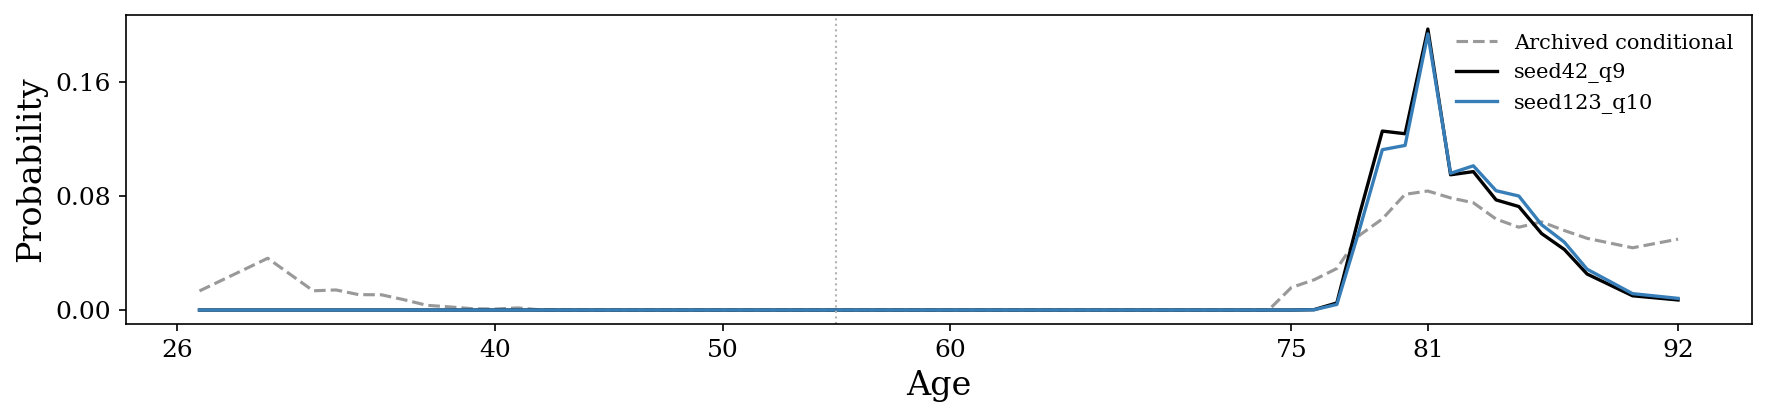

offset_l1_0.0001_it30_q9_b100 l2_1.2e-06 P(1) range: 0.6021063090792506 0.630824522607345 ; minimum P(age>55 | 1): 0.9999999999998839 ; mean TV: 0.2981148352554463


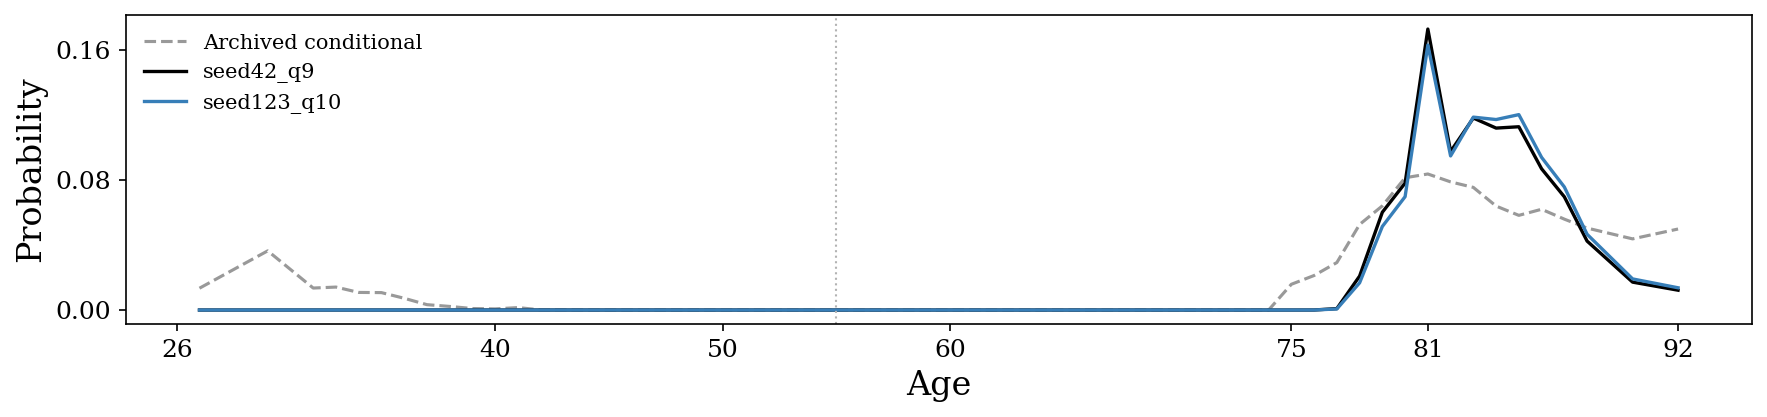

offset_l1_0.0001_it10_q9_b100 l2_1e-06 P(1) range: 0.8458185093101376 0.8503930557538452 ; minimum P(age>55 | 1): 0.9999999999998573 ; mean TV: 0.3439588008241333


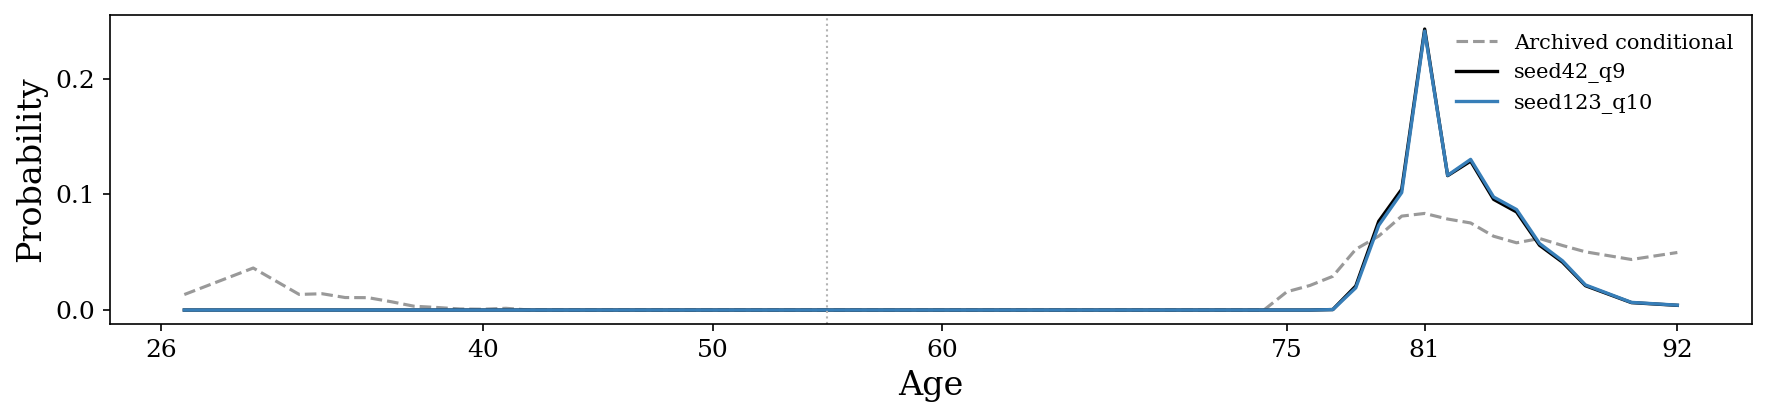

Selected exploratory recipe, not a calibration claim:
{
  "selection": "Exploratory: targets in both draws, then lowest mean TV to archive",
  "centered_features": true,
  "unpenalized_intercepts": true,
  "Delta": 1,
  "count_prior": [
    0.5,
    0.5
  ],
  "auxiliary_loss": "logistic",
  "auxiliary_penalty": "l1",
  "auxiliary_penalty_strength": 0.0001,
  "rho_updates": 30,
  "rho_damping": 0.25,
  "rho": [
    [
      0.2862796945753812,
      0.08243947668905242
    ],
    [
      0.08243947668905242,
      0.024041657623627317
    ]
  ],
  "rho_moment_residual": 0.11350346025668347,
  "posterior_loss": "logistic",
  "posterior_penalty": "l2",
  "posterior_penalty_strength": 1.5e-06,
  "response_model": "global-prevalence calibrated logistic offsets",
  "response_rate": 0.23167848699763594,
  "P1_range": [
    0.7176859802429055,
    0.7472084795605244
  ],
  "mass_above55_min": 0.9999999999999801,
  "mean_TV_to_archive": 0.2906731943937576,
  "state_draws": [
    512,
    1024
 

In [9]:

display(pd.read_csv(output/'independent_draw_check.csv'))
rows=[]
for rec in resolved:
    row={k:v for k,v in rec.items() if k!='conditional'}
    row['TV_to_reference']=.5*np.abs(rec['conditional']-reference_vector).sum()
    rows.append(row)
resolution=pd.DataFrame(rows)
resolution.to_csv(output/'penalty_resolution'/'summary_with_reference.csv',index=False)
ranked=resolution.groupby(['case','posterior_fit']).agg(P1_min=('P_1','min'),P1_max=('P_1','max'),
    mass_above55_min=('mass_above55','min'),mean_TV=('TV_to_reference','mean'),max_TV=('TV_to_reference','max'),
    moment_residual=('moment_residual','first'),max_fit_kkt=('max_fit_kkt','max'),FP_residual_max=('FP_residual_max','max')).reset_index()
ranked['meets_both_in_both']=(ranked.P1_min>.5)&(ranked.mass_above55_min>.5)
ranked=ranked.sort_values('mean_TV')
ranked.to_csv(output/'penalty_resolution'/'ranked_settings.csv',index=False)
print('Full final grid:')
with pd.option_context('display.max_rows',120):display(resolution)
print('Eligible in both realizations; closest curves first (exploratory):')
display(ranked[ranked.meets_both_in_both])
print('Conditional prior mass above 55:',np.mean(ages[locations]>55))
leaders=ranked[ranked.meets_both_in_both].head(3)
for row in leaders.itertuples():
    pairs=[r for r in resolved if r['case']==row.case and r['posterior_fit']==row.posterior_fit]
    print(row.case,row.posterior_fit,'P(1) range:',row.P1_min,row.P1_max,
          '; minimum P(age>55 | 1):',row.mass_above55_min,'; mean TV:',row.mean_TV)
    fig,ax=plt.subplots(figsize=(12,3))
    ax.plot(ref_ages,ref_mass,color='.6',ls='--',lw=1.5,label='Archived conditional')
    for rec in pairs:
        color='black' if rec['seed_label']=='seed42_q9' else '#377eb8'
        ax.plot(ages[locations],rec['conditional'],color=color,lw=1.6,label=rec['seed_label'])
    ax.axvline(55,color='.7',ls=':',lw=1);ax.set_xlabel('Age');ax.set_ylabel('Probability')
    ax.set_xticks([26,40,50,60,75,81,92]);ax.yaxis.set_major_locator(ticker.MaxNLocator(3));ax.legend(fontsize=10,frameon=False)
    fig.tight_layout();plt.show()
if len(leaders):
    winner=leaders.iloc[0]
    chosen=next(r for r in resolved if r['case']==winner.case and r['posterior_fit']==winner.posterior_fit)
    source=pickle.load((output/(winner.case+'.pkl')).open('rb'))
    recipe=dict(selection='Exploratory: targets in both draws, then lowest mean TV to archive',
        centered_features=True,unpenalized_intercepts=True,Delta=1,count_prior=[.5,.5],
        auxiliary_loss='logistic',auxiliary_penalty='l1',auxiliary_penalty_strength=1e-4,
        rho_updates=int(source['scenario']['iteration']),rho_damping=.25,
        rho=source['scenario']['rho'].tolist(),rho_moment_residual=float(winner.moment_residual),
        posterior_loss='logistic',posterior_penalty=chosen['penalty'],posterior_penalty_strength=chosen['strength'],
        response_model='global-prevalence calibrated logistic offsets',response_rate=float(y.mean()),
        P1_range=[float(winner.P1_min),float(winner.P1_max)],mass_above55_min=float(winner.mass_above55_min),
        mean_TV_to_archive=float(winner.mean_TV),state_draws=[512,1024],state_seeds=[42,123],state_max_nfev=100)
    (output/'selected_exploratory_setup.json').write_text(json.dumps(recipe,indent=2))
    print('Selected exploratory recipe, not a calibration claim:')
    print(json.dumps(recipe,indent=2))
